# 03. Pronóstico de la ventaja de patrimonio en Dota 2

**Douglas Pérez**  
**Carnet 22003865**

## 1. Introducción y objetivo

Quise estimar cómo cambia la ventaja de patrimonio de Radiant en los siguientes cinco minutos. Usé los snapshots de los minutos 10, 12, 15, 17 y 20 para predecir la ventaja del minuto 25. Elegí Dota 2 porque una misma ventaja al minuto 20 puede venir de trayectorias distintas.

Usé la versión 3 del dataset de Luis Alberto Sanchez Calderon, basada en telemetría de OpenDota. Esta revisión excluye partidas con snapshots de oro desalineados. [Dataset v3 en Zenodo](https://zenodo.org/records/23166182) · [OpenDota](https://www.opendota.com/)

## 2. Carga y análisis exploratorio (EDA)

Fijé los dos archivos de Zenodo con sus huellas MD5. Revisé cuántas partidas tienen observaciones en los minutos de interés, si hay snapshots repetidos y si faltan valores en las features. El minuto 25 se usa como target.

In [ ]:
from pathlib import Path
import hashlib
import shutil
import time
from urllib.error import URLError
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
ZENODO = "https://zenodo.org/records/23166182/files"
RUTA_DATOS = Path("dota2_zenodo_v3")
RUTA_DATOS.mkdir(exist_ok=True)
ARCHIVOS = {
    "DB_03_Live_Features_ANALYSIS_v3.csv": "f1c2362395ab39d5510a0a008d1cbe26",
    "Reproducibility_Experiment_211_Zenodo_v3.zip": "18ad19ff846fbeb903085ab4449792f3",
}


def huella_md5(path):
    with path.open("rb") as archivo:
        return hashlib.file_digest(archivo, "md5").hexdigest()


def descargar(nombre, md5):
    destino = RUTA_DATOS / nombre
    if destino.is_file() and huella_md5(destino) == md5:
        return destino
    temporal = destino.with_suffix(destino.suffix + ".part")
    for intento in range(1, 4):
        try:
            with urlopen(f"{ZENODO}/{nombre}?download=1", timeout=90) as origen, temporal.open("wb") as salida:
                shutil.copyfileobj(origen, salida, length=1024 * 1024)
            if huella_md5(temporal) != md5:
                raise ValueError(f"La huella de {nombre} difiere de la publicada en Zenodo.")
            temporal.replace(destino)
            return destino
        except (URLError, OSError, ValueError):
            if intento == 3:
                raise
            time.sleep(2 ** intento)


ruta_partidas, ruta_reproduccion = [descargar(n, md5) for n, md5 in ARCHIVOS.items()]
print("Archivos v3 verificados:", ", ".join(f"{p.name} ({p.stat().st_size / 1e6:.1f} MB)" for p in (ruta_partidas, ruta_reproduccion)))

Archivos v3 verificados: DB_03_Live_Features_ANALYSIS_v3.csv (223.0 MB), Reproducibility_Experiment_211_Zenodo_v3.zip (49.0 MB)


1,007,768 snapshots | 90,530 partidas | 0 pares partida-minuto duplicados
Valores faltantes en los minutos seleccionados: {'nw_adv': 0, 'kill_diff': 0, 'item_count_adv': 0, 'bkb_count_adv': 0}


,count,mean,std,min,25%,50%,75%,max
nw_adv,518090.0,121.24,5658.10,-41485.0,-2834.0,86.0,3051.0,48507.0
kill_diff,518090.0,0.25,7.59,-54.0,-4.0,0.0,4.0,57.0
item_count_adv,518090.0,0.02,2.28,-16.0,-1.0,0.0,1.0,16.0
bkb_count_adv,518090.0,-0.00,0.46,-4.0,0.0,0.0,0.0,4.0


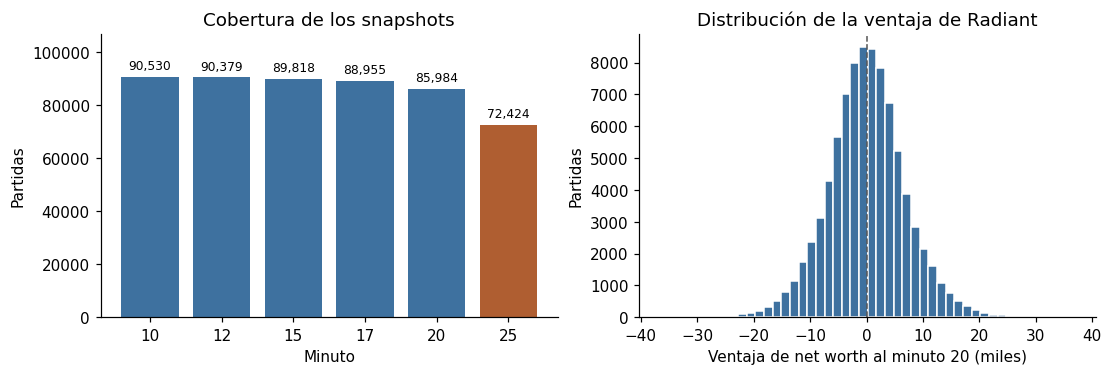

In [ ]:
MINUTOS_ENTRADA = [10, 12, 15, 17, 20]
MINUTO_TARGET = 25
MINUTOS = [*MINUTOS_ENTRADA, MINUTO_TARGET]
FEATURES = ["nw_adv", "kill_diff", "item_count_adv", "bkb_count_adv"]

original = pd.read_csv(ruta_partidas, usecols=["match_id", "minute", *FEATURES])
assert len(original) == 1_007_768
assert original["match_id"].nunique() == 90_530
assert not original.duplicated(["match_id", "minute"]).any()
observaciones = original.loc[original["minute"].isin(MINUTOS)].copy()
conteos = observaciones.groupby("minute")["match_id"].nunique().reindex(MINUTOS)
print(f"{len(original):,} snapshots | {original['match_id'].nunique():,} partidas | 0 pares partida-minuto duplicados")
print("Valores faltantes en los minutos seleccionados:", observaciones[FEATURES].isna().sum().to_dict())
display(observaciones[FEATURES].describe().T.round(2))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
barras = ejes[0].bar([str(m) for m in MINUTOS], conteos,
                   color=["#3e719f"] * len(MINUTOS_ENTRADA) + ["#af5e31"])
ejes[0].bar_label(barras, labels=[f"{n:,}" for n in conteos], padding=3, fontsize=8)
ejes[0].set(ylim=(0, conteos.max() * 1.18), xlabel="Minuto", ylabel="Partidas",
            title="Cobertura de los snapshots")
ejes[1].hist(observaciones.loc[observaciones["minute"].eq(20), "nw_adv"] / 1000, bins=48,
             color="#3e719f", edgecolor="white")
ejes[1].axvline(0, color="#555555", linestyle="--", linewidth=1)
ejes[1].set(xlabel="Ventaja de net worth al minuto 20 (miles)", ylabel="Partidas",
            title="Distribución de la ventaja de Radiant")
plt.show()

## 3. Preprocesamiento y split

Armé una secuencia por partida con los cinco snapshots de entrada. Conservé las partidas con la ventana completa y el target al minuto 25. Tomé net worth, kills y las diferencias en inventario y Black King Bars (BKB) como features. La duración y el ganador final se quedan fuera del input.

Entrené para predecir el cambio desde el minuto 20. Después sumé ese cambio a la última ventaja observada. Separé partidas completas por fecha y ajusté cada scaler solo con train.

In [ ]:
panel = observaciones.pivot(index="match_id", columns="minute", values=FEATURES)
entrada = np.stack([panel.xs(m, axis=1, level="minute")[FEATURES].to_numpy()
                    for m in MINUTOS_ENTRADA], axis=1)
ventaja_25 = panel[("nw_adv", MINUTO_TARGET)].to_numpy()
completas = np.isfinite(entrada).all(axis=(1, 2)) & np.isfinite(ventaja_25)
ids_partidas = panel.index.to_numpy()[completas]
x_secuencias = entrada[completas].astype(np.float32)
y_nw25 = ventaja_25[completas].astype(np.float32)
nw_20 = x_secuencias[:, -1, FEATURES.index("nw_adv")].copy()
delta = y_nw25 - nw_20

assert x_secuencias.shape == (len(ids_partidas), len(MINUTOS_ENTRADA), len(FEATURES))
assert len(np.unique(ids_partidas)) == len(ids_partidas)
assert len(ids_partidas) > 0 and np.isfinite(delta).all()
print(f"Partidas con ventana completa: {len(ids_partidas):,}")
print(f"Partidas excluidas por snapshots faltantes o valores no finitos: {original['match_id'].nunique() - len(ids_partidas):,}")
print(f"Input: {x_secuencias.shape[1]} snapshots × {x_secuencias.shape[2]} features por partida")
display(pd.DataFrame({"Minuto": MINUTOS, "Partidas con dato": conteos.to_numpy()}))

Partidas con ventana completa: 72,424
Partidas excluidas por snapshots faltantes o valores no finitos: 18,106
Input: 5 snapshots × 4 features por partida


,Minuto,Partidas con dato
0,10,90530
1,12,90379
2,15,89818
3,17,88955
4,20,85984
5,25,72424


In [ ]:
ARCHIVO_FECHAS = "Reproducibility_Experiment_211_v3/results/temporal_folds.csv"
with ZipFile(ruta_reproduccion) as paquete:
    with paquete.open(ARCHIVO_FECHAS) as archivo:
        cronologia = pd.read_csv(archivo, usecols=["match_id", "start_time"]).set_index("match_id")
assert cronologia.index.is_unique
fecha_segundos = cronologia["start_time"].reindex(ids_partidas)
assert fecha_segundos.notna().all()
inicio_utc = pd.to_datetime(fecha_segundos.to_numpy(), unit="s", utc=True)
dias = inicio_utc.floor("D")
orden = np.argsort(inicio_utc.asi8, kind="stable")

# Corto por día UTC para mantener todas las partidas del mismo día en un split.
corte_valid = dias[orden[int(0.70 * len(orden))]]
corte_test = dias[orden[int(0.85 * len(orden))]]
train_idx = orden[dias[orden] < corte_valid]
valid_idx = orden[(dias[orden] >= corte_valid) & (dias[orden] < corte_test)]
test_idx = orden[dias[orden] >= corte_test]
splits = {"train": train_idx, "validation": valid_idx, "test": test_idx}
assert all(len(indices) for indices in splits.values())
assert len(np.unique(np.concatenate(list(splits.values())))) == len(ids_partidas)
assert dias[train_idx].max() < dias[valid_idx].min()
assert dias[valid_idx].max() < dias[test_idx].min()

tabla_splits = pd.DataFrame([
    {"Split": nombre, "Partidas": len(indices), "Desde (UTC)": str(dias[indices].min().date()),
     "Hasta (UTC)": str(dias[indices].max().date())}
    for nombre, indices in splits.items()
]).set_index("Split")
display(tabla_splits)
print("Partidas compartidas entre splits: 0")

,Partidas,Desde (UTC),Hasta (UTC)
Split,,,
train,50690,2023-02-04,2025-04-06
validation,10786,2025-04-07,2025-09-19
test,10948,2025-09-20,2026-03-18


Partidas compartidas entre splits: 0


Scalers ajustados con 50,690 partidas de train
Desviación del cambio en train: 4,786 de patrimonio


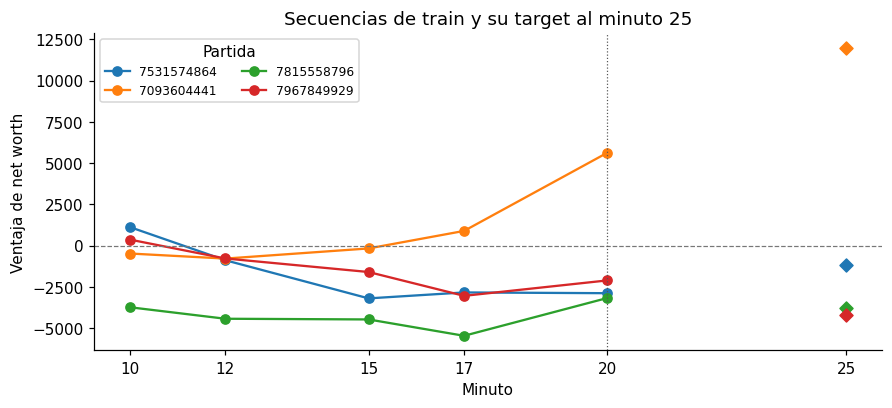

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_x = StandardScaler().fit(x_secuencias[train_idx].reshape(-1, len(FEATURES)))
scaler_delta = StandardScaler().fit(delta[train_idx, None])
x = scaler_x.transform(x_secuencias.reshape(-1, len(FEATURES))).reshape(x_secuencias.shape).astype(np.float32)
y = scaler_delta.transform(delta[:, None]).ravel().astype(np.float32)
assert np.isfinite(x).all() and np.isfinite(y).all()
assert np.allclose(x[train_idx].mean(axis=(0, 1)), 0, atol=1e-5)
print(f"Scalers ajustados con {len(train_idx):,} partidas de train")
print(f"Desviación del cambio en train: {scaler_delta.scale_[0]:,.0f} de patrimonio")

rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
for i in rng.choice(train_idx, size=4, replace=False):
    linea, = ax.plot(MINUTOS_ENTRADA, x_secuencias[i, :, 0], marker="o", label=str(ids_partidas[i]))
    ax.scatter(MINUTO_TARGET, y_nw25[i], marker="D", color=linea.get_color())
ax.axhline(0, linestyle="--", color="#777777", linewidth=0.8)
ax.axvline(20, linestyle=":", color="#555555", linewidth=0.8)
ax.set(xticks=MINUTOS, xlabel="Minuto", ylabel="Ventaja de net worth",
       title="Secuencias de train y su target al minuto 25")
ax.legend(title="Partida", ncol=2, fontsize=8)
plt.show()

## 4. Arquitecturas recurrentes

Comparé una LSTM con una GRU de una sola capa y 32 unidades. Ambas leen los cinco snapshots desde el minuto 10 hasta el 20. Las compuertas usan sigmoid y el estado candidato usa tanh. El último hidden state pasa por layer normalization y dropout de 0.10 antes de la salida lineal, que estima cuánto cambia la diferencia de net worth entre los equipos.

In [ ]:
import os
import random

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HIDDEN = 32


class PronosticoRecurrente(nn.Module):
    def __init__(self, tipo, n_features):
        super().__init__()
        capas = {"LSTM": nn.LSTM, "GRU": nn.GRU}
        self.recurrente = capas[tipo](n_features, HIDDEN, batch_first=True)
        self.salida = nn.Sequential(nn.LayerNorm(HIDDEN), nn.Dropout(0.10), nn.Linear(HIDDEN, 1))

    def forward(self, secuencia):
        estados, _ = self.recurrente(secuencia)
        return self.salida(estados[:, -1]).squeeze(-1)


print(f"PyTorch {torch.__version__} | Device: {DEVICE} | Seed: {SEED}")
for tipo in ("LSTM", "GRU"):
    modelo = PronosticoRecurrente(tipo, len(FEATURES))
    print(f"\n{tipo} | {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,} parámetros entrenables")
    print(modelo)
    with torch.inference_mode():
        forma = modelo.eval()(torch.zeros(2, len(MINUTOS_ENTRADA), len(FEATURES))).shape
    assert forma == (2,)
print(f"Input: {len(MINUTOS_ENTRADA)} × {len(FEATURES)} por partida | Output: un cambio estimado")

PyTorch 2.14.1+cpu | Device: cpu | Seed: 42

LSTM | 4,961 parámetros entrenables
PronosticoRecurrente(
  (recurrente): LSTM(4, 32, batch_first=True)
  (salida): Sequential(
    (0): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Dropout(p=0.1, inplace=False)
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)

GRU | 3,745 parámetros entrenables
PronosticoRecurrente(
  (recurrente): GRU(4, 32, batch_first=True)
  (salida): Sequential(
    (0): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Dropout(p=0.1, inplace=False)
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Input: 5 × 4 por partida | Output: un cambio estimado


## 5. Training y selección del checkpoint

Usé Huber loss para reducir el peso de cambios extremos durante el training. Entrené ambas redes con AdamW, learning rate de 0.002 y batch size de 1,024. Puse un máximo de 14 epochs, con early stopping de 4. Guardé el mejor checkpoint de cada red según el MAE de validation en unidades de net worth.

In [ ]:
LEARNING_RATE = 0.002
BATCH_SIZE = 1024
MAX_EPOCHS = 14
PATIENCE = 4
CHECKPOINTS = Path("checkpoints_rnn")
CHECKPOINTS.mkdir(exist_ok=True)
criterio = nn.HuberLoss(delta=1.0)
escala_delta = float(scaler_delta.scale_[0])


def crear_loader(indices, shuffle=False):
    dataset = TensorDataset(torch.from_numpy(x[indices]), torch.from_numpy(y[indices]))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED),
                      pin_memory=DEVICE.type == "cuda")


def pasar_epoch(modelo, loader, optimizer=None):
    training = optimizer is not None
    modelo.train(training)
    total_loss, suma_abs = 0.0, 0.0
    predicciones = []
    for secuencias, cambios in loader:
        lote = secuencias.to(DEVICE, non_blocking=True)
        objetivo = cambios.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training):
            pred = modelo(lote)
            loss = criterio(pred, objetivo)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(cambios)
        suma_abs += (pred.detach() - objetivo).abs().sum().item()
        predicciones.append(pred.detach().cpu().numpy())
    n = len(loader.dataset)
    return total_loss / n, suma_abs * escala_delta / n, np.concatenate(predicciones)


def entrenar(tipo, ruta):
    torch.manual_seed(SEED)
    modelo = PronosticoRecurrente(tipo, len(FEATURES)).to(DEVICE)
    optimizer = torch.optim.AdamW(modelo.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    train_loader = crear_loader(train_idx, shuffle=True)
    valid_loader = crear_loader(valid_idx)
    best_epoch, mejor_mae = 0, float("inf")
    historial = []
    for epoch in range(1, MAX_EPOCHS + 1):
        loss_train, mae_train, _ = pasar_epoch(modelo, train_loader, optimizer)
        loss_val, mae_val, _ = pasar_epoch(modelo, valid_loader)
        historial.append({"Epoch": epoch, "Train loss": loss_train, "Validation loss": loss_val,
                          "Train MAE": mae_train, "Validation MAE": mae_val})
        if mae_val < mejor_mae:
            best_epoch, mejor_mae = epoch, mae_val
            torch.save(modelo.state_dict(), ruta)
        print(f"{tipo} | epoch {epoch:02d} | train loss {loss_train:.4f} | "
              f"validation loss {loss_val:.4f} | MAE {mae_val:,.1f}", flush=True)
        if epoch - best_epoch >= PATIENCE:
            break
    assert ruta.is_file()
    return pd.DataFrame(historial), best_epoch

In [ ]:
historiales, rutas_checkpoint = {}, {}
filas_validacion = []
for tipo in ("LSTM", "GRU"):
    ruta = CHECKPOINTS / f"{tipo.lower()}_mejor.pt"
    historial, best_epoch = entrenar(tipo, ruta)
    historiales[tipo] = historial
    rutas_checkpoint[tipo] = ruta
    fila = historial.loc[historial["Epoch"].eq(best_epoch)].iloc[0]
    filas_validacion.append({"Modelo": tipo, "Best epoch": best_epoch,
                             "Validation MAE": fila["Validation MAE"],
                             "Validation loss": fila["Validation loss"]})

tabla_validacion = pd.DataFrame(filas_validacion).sort_values("Validation MAE")
seleccion = tabla_validacion.iloc[0]
modelo_elegido = PronosticoRecurrente(seleccion["Modelo"], len(FEATURES)).to(DEVICE)
modelo_elegido.load_state_dict(torch.load(rutas_checkpoint[seleccion["Modelo"]],
                                         map_location=DEVICE, weights_only=True))
display(tabla_validacion.round(4))
mae_persistencia_val = np.abs(y_nw25[valid_idx] - nw_20[valid_idx]).mean()
print(f"Baseline de persistencia | Validation MAE: {mae_persistencia_val:,.1f}")
print(f"Checkpoint seleccionado: {seleccion['Modelo']} | epoch {int(seleccion['Best epoch'])}")

LSTM | epoch 01 | train loss 0.3974 | validation loss 0.4216 | MAE 3,788.3
LSTM | epoch 02 | train loss 0.3834 | validation loss 0.4203 | MAE 3,781.6
LSTM | epoch 03 | train loss 0.3815 | validation loss 0.4171 | MAE 3,759.0
LSTM | epoch 04 | train loss 0.3798 | validation loss 0.4177 | MAE 3,764.0
LSTM | epoch 05 | train loss 0.3789 | validation loss 0.4173 | MAE 3,763.1
LSTM | epoch 06 | train loss 0.3786 | validation loss 0.4171 | MAE 3,760.7
LSTM | epoch 07 | train loss 0.3777 | validation loss 0.4156 | MAE 3,750.6
LSTM | epoch 08 | train loss 0.3777 | validation loss 0.4172 | MAE 3,760.3
LSTM | epoch 09 | train loss 0.3783 | validation loss 0.4163 | MAE 3,755.2
LSTM | epoch 10 | train loss 0.3776 | validation loss 0.4160 | MAE 3,752.3
LSTM | epoch 11 | train loss 0.3775 | validation loss 0.4153 | MAE 3,748.2
LSTM | epoch 12 | train loss 0.3775 | validation loss 0.4153 | MAE 3,748.3
LSTM | epoch 13 | train loss 0.3775 | validation loss 0.4176 | MAE 3,764.6
LSTM | epoch 14 | train l

,Modelo,Best epoch,Validation MAE,Validation loss
1,GRU,12,3745.6985,0.4149
0,LSTM,11,3748.1670,0.4153


Baseline de persistencia | Validation MAE: 4,140.9
Checkpoint seleccionado: GRU | epoch 12


## 6. Evaluación en test

Revisé el loss por epoch y usé MAE para comparar los checkpoints. En test contrasté la red elegida con dos baselines. Persistencia mantiene la ventaja del minuto 20 y tendencia lineal repite el cambio que hubo entre los minutos 15 y 20. Usé MAE y RMSE en unidades de net worth para ver el error típico y cuánto pesan los errores grandes.

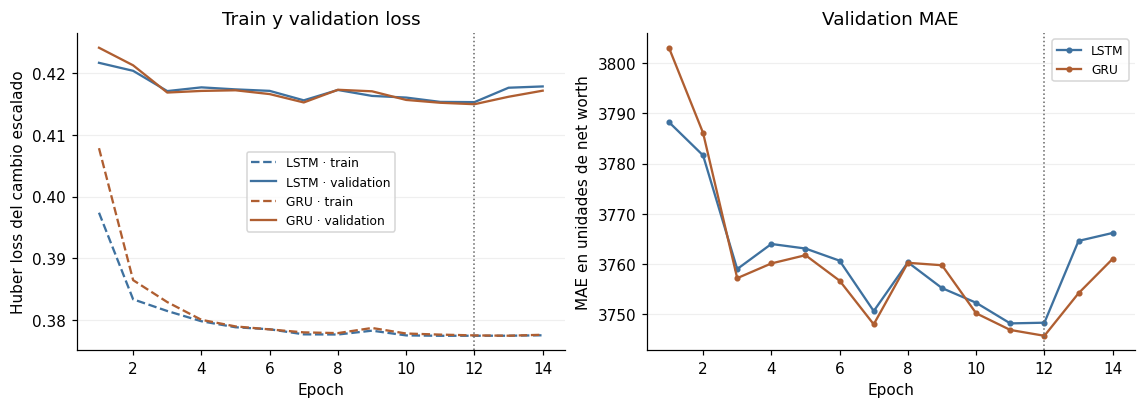

In [ ]:
colores = ["#3e719f", "#af5e31"]
fig, ejes = plt.subplots(1, 2, figsize=(10.3, 3.6), layout="constrained")
for color, (tipo, historial) in zip(colores, historiales.items()):
    ejes[0].plot(historial["Epoch"], historial["Train loss"], linestyle="--", color=color,
                 label=f"{tipo} · train")
    ejes[0].plot(historial["Epoch"], historial["Validation loss"], color=color,
                 label=f"{tipo} · validation")
    ejes[1].plot(historial["Epoch"], historial["Validation MAE"], color=color, marker=".", label=tipo)
for ax in ejes:
    ax.axvline(seleccion["Best epoch"], linestyle=":", color="#666666", linewidth=1)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)
ejes[0].set(xlabel="Epoch", ylabel="Huber loss del cambio escalado", title="Train y validation loss")
ejes[1].set(xlabel="Epoch", ylabel="MAE en unidades de net worth", title="Validation MAE")
plt.show()

,MAE,RMSE,R²
GRU,3694.8096,4689.0660,0.7308
Persistencia,4143.3877,5113.9595,0.6798
Tendencia lineal,3963.6418,5078.2200,0.6843


Test Huber loss del cambio escalado: 0.4061
Reducción de MAE frente a persistencia: +10.83 %


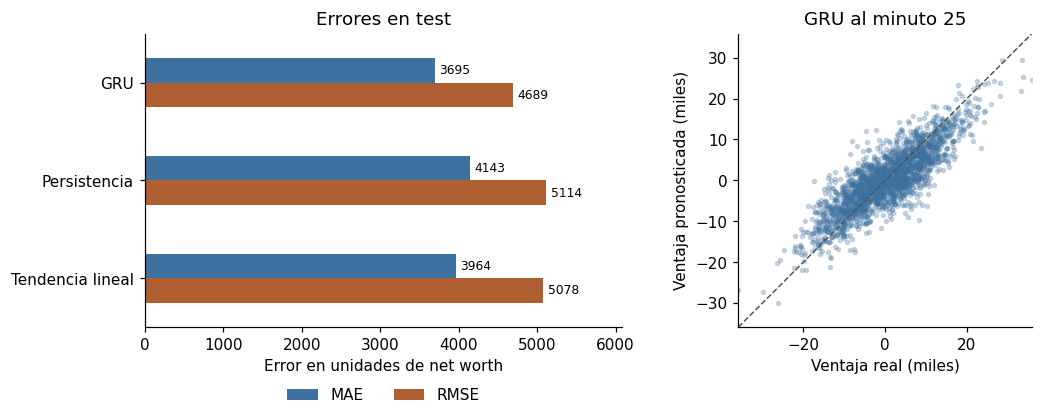

,Partidas,MAE_modelo,MAE_persistencia
Cambio absoluto real,,,
"Menos de 2,000",3130,1436.0,988.1
"2,000 a menos de 5,000",4089,2857.0,3428.8
"5,000 o más",3729,6509.4,7575.3


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_loader = crear_loader(test_idx)
loss_test, mae_test, pred_escalada = pasar_epoch(modelo_elegido, test_loader)
cambio_estimado = scaler_delta.inverse_transform(pred_escalada[:, None]).ravel()
real = y_nw25[test_idx]
ultimo = nw_20[test_idx]
nw_15 = x_secuencias[test_idx, MINUTOS_ENTRADA.index(15), FEATURES.index("nw_adv")]
pronosticos = {
    str(seleccion["Modelo"]): ultimo + cambio_estimado,
    "Persistencia": ultimo,
    "Tendencia lineal": ultimo + (ultimo - nw_15),
}
assert all(len(p) == len(real) and np.isfinite(p).all() for p in pronosticos.values())
fila_modelo = str(seleccion["Modelo"])
pred = pronosticos[fila_modelo]
metricas_test = pd.DataFrame({nombre: {
    "MAE": mean_absolute_error(real, estimado),
    "RMSE": np.sqrt(mean_squared_error(real, estimado)),
    "R²": r2_score(real, estimado),
} for nombre, estimado in pronosticos.items()}).T
assert np.isclose(mae_test, metricas_test.loc[fila_modelo, "MAE"], rtol=1e-5)
display(metricas_test.round(4))
print(f"Test Huber loss del cambio escalado: {loss_test:.4f}")
diferencia_mae = 100 * (1 - metricas_test.loc[fila_modelo, "MAE"] / metricas_test.loc["Persistencia", "MAE"])
print(f"Reducción de MAE frente a persistencia: {diferencia_mae:+.2f} %")

fig, ejes = plt.subplots(1, 2, figsize=(10.2, 3.7), layout="constrained")
metricas_test[["MAE", "RMSE"]].plot.barh(ax=ejes[0], color=["#3e719f", "#af5e31"])
for barras in ejes[0].containers:
    ejes[0].bar_label(barras, fmt="%.0f", padding=3, fontsize=8)
ejes[0].set(xlabel="Error en unidades de net worth", title="Errores en test",
            xlim=(0, metricas_test["RMSE"].max() * 1.19))
ejes[0].invert_yaxis()
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)

indices_grafica = rng.choice(len(real), size=min(2200, len(real)), replace=False)
a, b = real[indices_grafica] / 1000, pred[indices_grafica] / 1000
limites = [min(a.min(), b.min()), max(a.max(), b.max())]
ejes[1].scatter(a, b, s=7, alpha=0.25, color="#3e719f")
ejes[1].plot(limites, limites, linestyle="--", color="#555555", linewidth=1)
ejes[1].set(xlabel="Ventaja real (miles)", ylabel="Ventaja pronosticada (miles)",
            xlim=limites, ylim=limites, title=f"{fila_modelo} al minuto 25")
ejes[1].set_aspect("equal", adjustable="box")
plt.show()

cambio_real = np.abs(real - ultimo)
tramos = pd.cut(cambio_real, bins=[-np.inf, 2000, 5000, np.inf], right=False,
               labels=["Menos de 2,000", "2,000 a menos de 5,000", "5,000 o más"])
error_por_tramo = pd.DataFrame({"Cambio absoluto real": tramos,
                               f"Error {fila_modelo}": np.abs(real - pred).astype(np.float64),
                               "Error persistencia": np.abs(real - ultimo).astype(np.float64)})
display(error_por_tramo.groupby("Cambio absoluto real", observed=True).agg(
    Partidas=(f"Error {fila_modelo}", "size"),
    MAE_modelo=(f"Error {fila_modelo}", "mean"),
    MAE_persistencia=("Error persistencia", "mean"),
).round(1))

### Ejemplos de pronósticos

Tomé dos partidas con error pequeño y dos con error grande. Dibujé el historial hasta el minuto 20 y comparé el valor observado al minuto 25 con los pronósticos de la red y de persistencia.

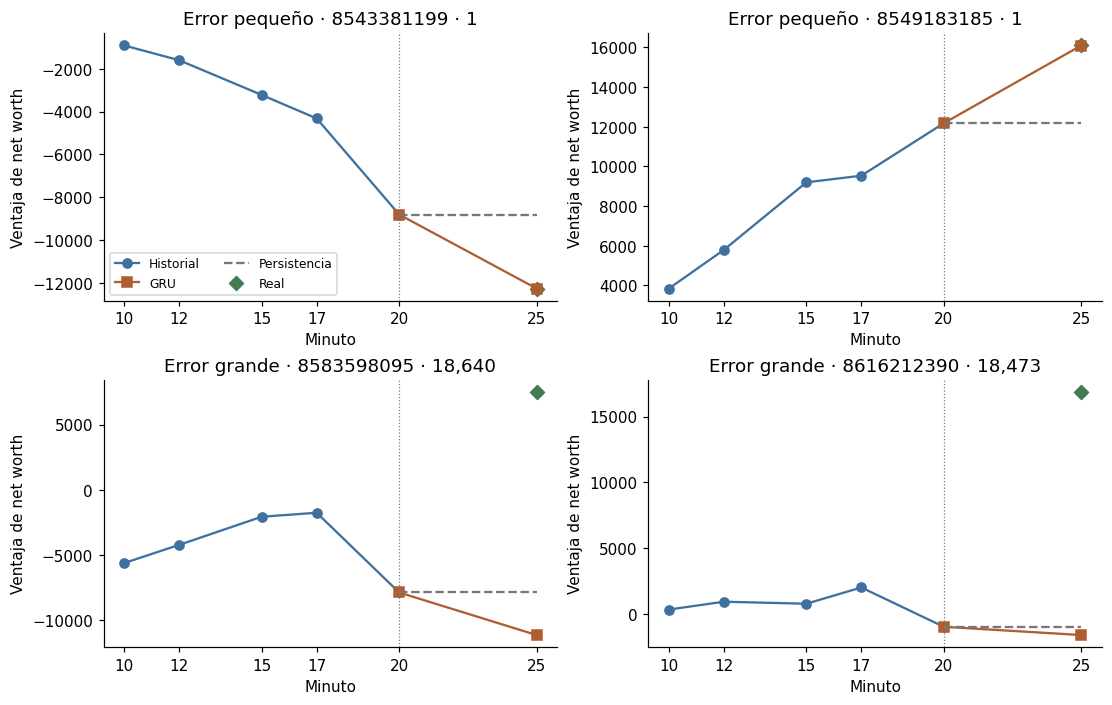

,Partida,Net worth 20,Real 25,Pronóstico 25,Error absoluto
0,8543381199,-8809.0,-12267.0,-12266.3,0.7
1,8549183185,12178.0,16095.0,16093.6,1.4
2,8583598095,-7875.0,7502.0,-11137.9,18639.9
3,8616212390,-978.0,16868.0,-1605.0,18473.0


In [ ]:
errores = np.abs(pred - real)
orden_errores = np.argsort(errores)
ejemplos = np.r_[orden_errores[:2], orden_errores[-2:][::-1]]
assert len(set(ejemplos)) == 4
filas_muestra = []
fig, ejes = plt.subplots(2, 2, figsize=(10, 6.3), layout="constrained")
for k, (ax, j) in enumerate(zip(ejes.flat, ejemplos)):
    i = test_idx[j]
    partido = ids_partidas[i]
    filas_muestra.append({"Partida": partido, "Net worth 20": ultimo[j], "Real 25": real[j],
                          "Pronóstico 25": pred[j], "Error absoluto": errores[j]})
    ax.plot(MINUTOS_ENTRADA, x_secuencias[i, :, 0], color="#3e719f", marker="o", label="Historial")
    ax.plot([20, 25], [ultimo[j], pred[j]], color="#af5e31", marker="s", label=fila_modelo)
    ax.plot([20, 25], [ultimo[j], ultimo[j]], color="#777777", linestyle="--", label="Persistencia")
    ax.scatter(25, real[j], color="#437b54", marker="D", s=42, label="Real")
    ax.axvline(20, color="#777777", linestyle=":", linewidth=0.8)
    titulo = "Error pequeño" if k < 2 else "Error grande"
    ax.set(xticks=MINUTOS, xlabel="Minuto", ylabel="Ventaja de net worth",
           title=f"{titulo} · {partido} · {errores[j]:,.0f}")
ejes[0, 0].legend(fontsize=8, ncol=2)
plt.show()
muestra = pd.DataFrame(filas_muestra)
columnas_valores = muestra.columns.drop("Partida")
muestra[columnas_valores] = muestra[columnas_valores].astype(float).round(1)
display(muestra)

## 7. Análisis y conclusiones

Elegí la GRU del epoch 12 por su validation MAE de 3,745.7. La LSTM quedó cerca, con 3,748.2. En 10,948 partidas de test, la GRU obtuvo **MAE de 3,694.81** y **RMSE de 4,689.07**. El MAE fue 10.83 % menor que el de persistencia.

Persistencia tuvo menor MAE cuando el cambio real fue menor de 2,000. Para cambios absolutos de 5,000 o más, la GRU bajó el MAE de 7,575.3 a 6,509.4. Aun así, hubo remontadas que no anticipó. En la partida 8583598095, Radiant pasó de −7,875 a +7,502 y la GRU pronosticó −11,138.

La evaluación cubre partidas profesionales con la ventana completa hasta el minuto 25. En una siguiente prueba mediría el error por parche y agregaría información sobre objetivos del mapa observados hasta el minuto 20.